# 12. Проверка обновленного представления облачных групп METAR

## 1. Область изменения и сохраненные версии

Версия `cloud-v2` поддерживает `///CB` и `///TCU`, сохраняя известный тип и
неизвестные количество/высоту, и согласует сравнение полностью отсутствующей
облачной группы `/////////` с python-metar. Значение коротких групп описано в
[Météo-France, Guide aviation 2021, с. 17](https://meteofrance.fr/sites/meteofrance.fr/files/files/editorial/guide_aviation_2021.pdf).

Предыдущие модули и файлы остаются на месте, а новая версия хранится в
`data/full_cloud_v2/`: `reports/`, `features/`, `numeric_features/`.
Числовые маски CP-10 сохраняются. Наличие типа облака не подтверждает
его количественные характеристики или время получения METAR к C40.


In [1]:
from pathlib import Path
import hashlib, json, sys
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from IPython.display import display, Markdown, HTML
from html import escape
from cycler import cycler

BASE = Path.cwd().resolve()
while not (BASE / 'reports/03_pilot_manifest.json').exists():
    if BASE == BASE.parent:
        raise FileNotFoundError('Не найдена папка europe/weather с выполненным пилотом')
    BASE = BASE.parent
PROJECT = BASE.parents[1]
R, F, DATA = BASE / 'reports', BASE / 'figures', BASE / 'data'
F.mkdir(exist_ok=True)
sys.path.insert(0, str(BASE / 'scripts'))
manifest = json.loads((R / '03_pilot_manifest.json').read_text(encoding='utf8'))
def sha(path):
    with path.open('rb') as stream:
        return hashlib.file_digest(stream, 'sha256').hexdigest()
assert sha(PROJECT / 'europe/data/analytical/06_05_cases_excluded.parquet') == manifest['input_sha256']
for source in manifest['downloads']:
    path = DATA / 'raw' / f"{source['airport']}_{source['month']}.csv"
    assert sha(path) == source['sha256']

GREEN, CORAL, LIGHT_GREEN, LIGHT_CORAL = '#00897B', '#D65A4A', '#80CBC4', '#E69A90'
plt.rcParams.update({'figure.dpi':120, 'font.size':11, 'axes.spines.top':False,
    'axes.spines.right':False, 'axes.grid':True, 'grid.alpha':.16,
    'axes.prop_cycle':cycler(color=[CORAL, GREEN, LIGHT_CORAL, LIGHT_GREEN])})
pd.set_option('display.max_columns', 20)
pd.set_option('display.max_rows', 30)
pd.set_option('display.max_colwidth', 100)
def save(name):
    plt.tight_layout()
    for ext in ['png', 'svg']:
        plt.savefig(F / f'{name}.{ext}', bbox_inches='tight')
    plt.show()
def readable_table(frame):
    html = frame.to_html(index=False, escape=True)
    display(HTML('<div style="max-width:100%;overflow:auto">' + html + '</div>'))


In [2]:
application=json.loads((R/'21_cloud_v2_application.json').read_text(encoding='utf8'))
cases=pd.read_csv(R/'21_cloud_v2_cases.csv',keep_default_na=False)
changes=pd.read_csv(R/'21_cloud_v2_field_changes.csv',keep_default_na=False)
coverage=pd.read_csv(R/'21_cloud_v2_coverage.csv')
remaining=pd.read_csv(R/'21_cloud_v2_residuals.csv',keep_default_na=False)
assert application['all_source_rows_present_once'] and application['previous_files_unchanged']
assert application['numeric_masks_preserved'] and application['non_cloud_numeric_values_unchanged']
assert application['station_time_and_metar_links_unchanged']
assert application['rows']==coverage.rows.sum()==6331485 and application['go_arounds']==18349
assert cases.metar_id.is_unique and len(cases)==application['unique_target_messages']
assert len(remaining)==application['remaining_residual_messages']
assert application['rows_deleted']==0 and not application['training_executed']
display(pd.DataFrame([{key:value for key,value in application.items() if key!='jobs'}]))
readable_table(coverage)


,version,rows,go_arounds,input_sha256,unique_target_messages,unique_changed_messages,resolved_full_messages,remaining_residual_messages,pilot_rows_unchanged,all_source_rows_present_once,previous_files_unchanged,numeric_masks_preserved,station_time_and_metar_links_unchanged,non_cloud_numeric_values_unchanged,rows_deleted,training_executed,implementation_sha256,decoder_sha256,original_decoder_sha256
0,cloud-v2,6331485,18349,1111c7480ff7615042a332c586c8f60459bf5d6000da11ea4d0ec2a773fc0719,1339,1339,1323,1102,18439,True,True,True,True,True,0,False,cf04f5427525c152df25707b81076390846e70ab3d26f4639648b857fdf8eed3,54afeeb8bf99def8d6f1a4dd880691cdc34c01a890903b8108d1fdd11322b8e1,6c1fc46f433a30a870d48d20c0c0e9c7d342e40a8612194a412ba1b618faf9bb


airport,year,rows,target_messages,linked_target_rows,linked_target_go_arounds,old_decoded_rows,new_decoded_rows,old_core_rows,new_core_rows
EDDB,2019,28762,57,89,0,28673,28762,28673,28762
EDDB,2020,13117,58,30,0,13087,13117,13087,13117
EDDB,2021,35640,40,47,0,35582,35629,35582,35629
EDDB,2022,50306,16,52,0,50227,50274,50242,50294
EDDB,2023,20511,1,4,0,20505,20509,20507,20511
EDDF,2019,218773,11,104,0,218655,218759,218669,218773
EDDF,2020,96515,25,94,0,96421,96515,96421,96515
EDDF,2021,118807,18,121,3,118635,118756,118635,118756
EDDF,2022,159344,14,162,1,159082,159142,159176,159338
EDDF,2023,11521,4,45,0,11467,11502,11476,11521


## 2. Что изменилось в представлении

Для короткой группы количество записывается неизвестным, высота — пропуском,
тип CB/TCU сохраняется. При неизвестном количестве хотя бы одного слоя
потолок BKN/OVC не считается полностью установленным. Высота известного слоя
может сохраняться как `lowest_known_cloud_base_ft`; это сводка известных
высот, а не доказательство высоты самого низкого возможного облака.

Для девяти слешей исходный токен и неизвестные компоненты остаются в данных.
Исправляется сравнение с парсером, который не создает слой для полностью
отсутствующих характеристик. Неизвестная облачность не превращается в CAVOK.


,Измененных сообщений
field,
cloud_state,277
cumulonimbus_reported,419
towering_cumulus_reported,448
cloud_ceiling_ft,572
cloud_ceiling_relation,572
cloud_layers_json,867
cloud_ceiling_status,867
cloud_amount_unavailable,867
cloud_tokens,867


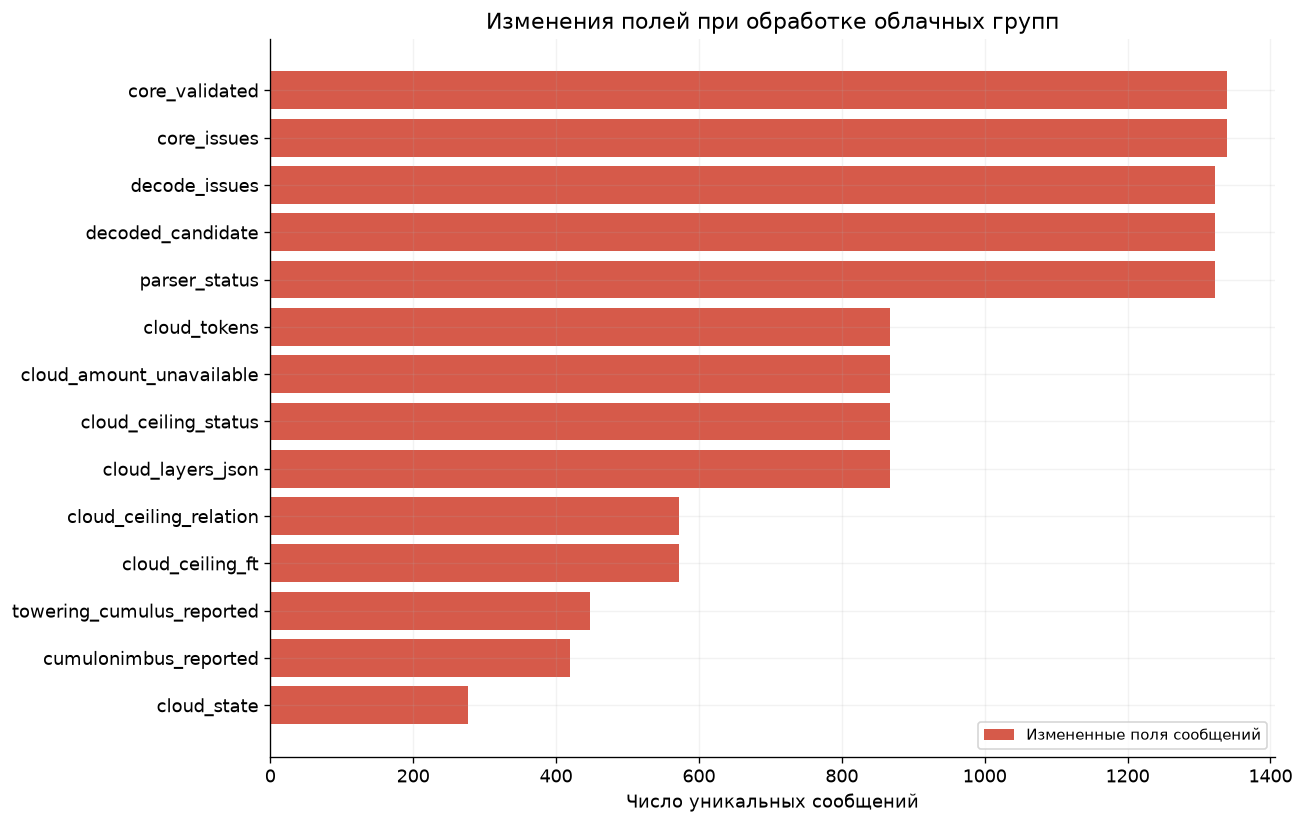

old_decoded_candidate,new_decoded_candidate,old_core_validated,new_core_validated,messages
False,False,False,True,16
False,True,False,True,1323


### Исходная группа ///TCU

metar_id,station,metar_utc,metar,changed_fields,old_decoded_candidate,new_decoded_candidate,old_core_validated,new_core_validated,remaining_issues
9d53d0c55e0f752b85f0a891b551c55ea5f0b1b0ca6329564015b13a3db550d8,LFPG,2019-09-24 07:30:00+00:00,LFPG 240730Z AUTO 15024KT 9999 ///TCU 16/12 Q1006 TEMPO 22015G25KT 2000 RA OVC008,cloud_tokens;cloud_state;cloud_layers_json;cloud_ceiling_status;cloud_amount_unavailable;towering_cumulus_reported;parser_status;decode_issues;decoded_candidate;core_validated;core_issues,False,True,False,True,
ec0257b16f0b70778a9e987d9d997cd325e86f4fad2dfc4d4fa5be8b7cd62809,LFPG,2019-09-24 08:30:00+00:00,LFPG 240830Z AUTO 19015KT 9999 -RA BKN017/// OVC110/// ///TCU 16/13 Q1009 TEMPO 22015G25KT 2000 RA OVC008,cloud_tokens;cloud_layers_json;cloud_ceiling_ft;cloud_ceiling_relation;cloud_ceiling_status;cloud_amount_unavailable;towering_cumulus_reported;parser_status;decode_issues;decoded_candidate;core_validated;core_issues,False,True,False,True,
d37a216bd0aa9e1779ae6a6e38e7da0cc0590a23ea5112d6a46d82a5da2a40e2,LFPG,2019-09-24 09:30:00+00:00,LFPG 240930Z AUTO 17011KT 9999 OVC016/// ///TCU 16/13 Q1008 TEMPO 22015G25KT 2000 RA OVC008,cloud_tokens;cloud_layers_json;cloud_ceiling_ft;cloud_ceiling_relation;cloud_ceiling_status;cloud_amount_unavailable;towering_cumulus_reported;parser_status;decode_issues;decoded_candidate;core_validated;core_issues,False,True,False,True,


metar_id,station,metar_utc,field,old_value,new_value
9d53d0c55e0f752b85f0a891b551c55ea5f0b1b0ca6329564015b13a3db550d8,LFPG,2019-09-24 07:30:00+00:00,cloud_tokens,,///TCU
9d53d0c55e0f752b85f0a891b551c55ea5f0b1b0ca6329564015b13a3db550d8,LFPG,2019-09-24 07:30:00+00:00,cloud_state,not_reported,layers
9d53d0c55e0f752b85f0a891b551c55ea5f0b1b0ca6329564015b13a3db550d8,LFPG,2019-09-24 07:30:00+00:00,cloud_layers_json,[],"[{""cover"": ""///"", ""height_ft"": null, ""height_relation"": ""missing"", ""kind"": ""TCU"", ""raw"": ""///TCU""}]"
9d53d0c55e0f752b85f0a891b551c55ea5f0b1b0ca6329564015b13a3db550d8,LFPG,2019-09-24 07:30:00+00:00,cloud_ceiling_status,no_bkn_ovc_group,amount_unknown
9d53d0c55e0f752b85f0a891b551c55ea5f0b1b0ca6329564015b13a3db550d8,LFPG,2019-09-24 07:30:00+00:00,cloud_amount_unavailable,False,True
9d53d0c55e0f752b85f0a891b551c55ea5f0b1b0ca6329564015b13a3db550d8,LFPG,2019-09-24 07:30:00+00:00,towering_cumulus_reported,False,True
9d53d0c55e0f752b85f0a891b551c55ea5f0b1b0ca6329564015b13a3db550d8,LFPG,2019-09-24 07:30:00+00:00,parser_status,needs_review,ok
9d53d0c55e0f752b85f0a891b551c55ea5f0b1b0ca6329564015b13a3db550d8,LFPG,2019-09-24 07:30:00+00:00,decode_issues,parser_value_disagreement_cloud_layers,
9d53d0c55e0f752b85f0a891b551c55ea5f0b1b0ca6329564015b13a3db550d8,LFPG,2019-09-24 07:30:00+00:00,decoded_candidate,False,True
9d53d0c55e0f752b85f0a891b551c55ea5f0b1b0ca6329564015b13a3db550d8,LFPG,2019-09-24 07:30:00+00:00,core_validated,False,True


### Исходная группа ///CB

metar_id,station,metar_utc,metar,changed_fields,old_decoded_candidate,new_decoded_candidate,old_core_validated,new_core_validated,remaining_issues
91cd1560dbd04ec4828251aed69747982ae5f9ae32acf708664c081839f64a1d,LFPG,2019-09-24 16:00:00+00:00,LFPG 241600Z AUTO 23007KT 9999 FEW019/// SCT044/// ///CB 20/15 Q1005 TEMPO 22015G30KT 3000 TSRA,cloud_tokens;cloud_layers_json;cloud_ceiling_status;cloud_amount_unavailable;cumulonimbus_reported;parser_status;decode_issues;decoded_candidate;core_validated;core_issues,False,True,False,True,
5eb3fad0e9ab09487a1c31735a95cd4f8833d3df71a6958f8466ce61c9be97c8,LFPG,2019-09-24 16:30:00+00:00,LFPG 241630Z AUTO 26009G25KT 9999 2100 RA FEW020/// SCT030/// BKN045/// ///CB 19/16 Q1006 TEMPO 4000 -SHRA BECMG 20010KT,cloud_tokens;cloud_layers_json;cloud_ceiling_ft;cloud_ceiling_relation;cloud_ceiling_status;cloud_amount_unavailable;cumulonimbus_reported;parser_status;decode_issues;decoded_candidate;core_validated;core_issues,False,True,False,True,
08bf5a8bc4764d306d19d49719ddfc12d7f2196dd452b1fabbd9672840540958,LFPG,2019-09-24 17:00:00+00:00,LFPG 241700Z AUTO 24005KT 9999 FEW021/// SCT070/// OVC086/// ///CB 16/14 Q1006 TEMPO 22015G30KT 4000 -SHRA,cloud_tokens;cloud_layers_json;cloud_ceiling_ft;cloud_ceiling_relation;cloud_ceiling_status;cloud_amount_unavailable;cumulonimbus_reported;parser_status;decode_issues;decoded_candidate;core_validated;core_issues,False,True,False,True,


metar_id,station,metar_utc,field,old_value,new_value
91cd1560dbd04ec4828251aed69747982ae5f9ae32acf708664c081839f64a1d,LFPG,2019-09-24 16:00:00+00:00,cloud_tokens,FEW019/// SCT044///,FEW019/// SCT044/// ///CB
91cd1560dbd04ec4828251aed69747982ae5f9ae32acf708664c081839f64a1d,LFPG,2019-09-24 16:00:00+00:00,cloud_layers_json,"[{""cover"": ""FEW"", ""height_ft"": 1900, ""height_relation"": ""reported_step"", ""kind"": ""///"", ""raw"": ""FEW019///""}, {""cover"": ""SCT"", ""height_ft"": 4400, ""height_relation"": ""reported_step"", ""kind"": ""///"", ""raw"": ""SCT044///""}]","[{""cover"": ""FEW"", ""height_ft"": 1900, ""height_relation"": ""reported_step"", ""kind"": ""///"", ""raw"": ""FEW019///""}, {""cover"": ""SCT"", ""height_ft"": 4400, ""height_relation"": ""reported_step"", ""kind"": ""///"", ""raw"": ""SCT044///""}, {""cover"": ""///"", ""height_ft"": null, ""height_relation"": ""missing"", ""kind"": ""CB"", ""raw"": ""///CB""}]"
91cd1560dbd04ec4828251aed69747982ae5f9ae32acf708664c081839f64a1d,LFPG,2019-09-24 16:00:00+00:00,cloud_ceiling_status,no_bkn_ovc_group,amount_unknown
91cd1560dbd04ec4828251aed69747982ae5f9ae32acf708664c081839f64a1d,LFPG,2019-09-24 16:00:00+00:00,cloud_amount_unavailable,False,True
91cd1560dbd04ec4828251aed69747982ae5f9ae32acf708664c081839f64a1d,LFPG,2019-09-24 16:00:00+00:00,cumulonimbus_reported,False,True
91cd1560dbd04ec4828251aed69747982ae5f9ae32acf708664c081839f64a1d,LFPG,2019-09-24 16:00:00+00:00,parser_status,needs_review,ok
91cd1560dbd04ec4828251aed69747982ae5f9ae32acf708664c081839f64a1d,LFPG,2019-09-24 16:00:00+00:00,decode_issues,parser_value_disagreement_cloud_layers,
91cd1560dbd04ec4828251aed69747982ae5f9ae32acf708664c081839f64a1d,LFPG,2019-09-24 16:00:00+00:00,decoded_candidate,False,True
91cd1560dbd04ec4828251aed69747982ae5f9ae32acf708664c081839f64a1d,LFPG,2019-09-24 16:00:00+00:00,core_validated,False,True
91cd1560dbd04ec4828251aed69747982ae5f9ae32acf708664c081839f64a1d,LFPG,2019-09-24 16:00:00+00:00,core_issues,parser_value_disagreement_cloud_layers,


### Исходная группа /////////

metar_id,station,metar_utc,metar,changed_fields,old_decoded_candidate,new_decoded_candidate,old_core_validated,new_core_validated,remaining_issues
22c6b537bea98615d6e3fab18f7e3aaec39426f27d8d1211f38af35eda598a73,EDDB,2019-01-12 10:20:00+00:00,EDDB 121020Z AUTO 27016KT //// R25R/P2000N R25L/P2000N // ///////// 06/04 Q1012 TEMPO 3000 -RADZ BKN007,parser_status;decode_issues;decoded_candidate;core_validated;core_issues,False,True,False,True,
b65867890f84d14e50ec99c6cca5fc84d7cce49a987ed89d301acf89f5f886e1,EDDB,2019-01-17 12:20:00+00:00,EDDB 171220Z AUTO 25014KT //// R25R/P2000N R25L/P2000N // ///////// 07/01 Q0999 TEMPO 24015G25KT,parser_status;decode_issues;decoded_candidate;core_validated;core_issues,False,True,False,True,
59ea55c2d87b5b279ca5c9d5bb5bea5d86b7830f8ec30bd7edda9f313681b55b,EDDB,2019-01-25 20:50:00+00:00,EDDB 252050Z AUTO 23009KT //// R25R/P2000N R25L/P2000N // ///////// M03/M08 Q1011 NOSIG,parser_status;decode_issues;decoded_candidate;core_validated;core_issues,False,True,False,True,


metar_id,station,metar_utc,field,old_value,new_value
22c6b537bea98615d6e3fab18f7e3aaec39426f27d8d1211f38af35eda598a73,EDDB,2019-01-12 10:20:00+00:00,parser_status,needs_review,ok
22c6b537bea98615d6e3fab18f7e3aaec39426f27d8d1211f38af35eda598a73,EDDB,2019-01-12 10:20:00+00:00,decode_issues,parser_value_disagreement_cloud_layers,
22c6b537bea98615d6e3fab18f7e3aaec39426f27d8d1211f38af35eda598a73,EDDB,2019-01-12 10:20:00+00:00,decoded_candidate,False,True
22c6b537bea98615d6e3fab18f7e3aaec39426f27d8d1211f38af35eda598a73,EDDB,2019-01-12 10:20:00+00:00,core_validated,False,True
22c6b537bea98615d6e3fab18f7e3aaec39426f27d8d1211f38af35eda598a73,EDDB,2019-01-12 10:20:00+00:00,core_issues,parser_value_disagreement_cloud_layers,
b65867890f84d14e50ec99c6cca5fc84d7cce49a987ed89d301acf89f5f886e1,EDDB,2019-01-17 12:20:00+00:00,parser_status,needs_review,ok
b65867890f84d14e50ec99c6cca5fc84d7cce49a987ed89d301acf89f5f886e1,EDDB,2019-01-17 12:20:00+00:00,decode_issues,parser_value_disagreement_cloud_layers,
b65867890f84d14e50ec99c6cca5fc84d7cce49a987ed89d301acf89f5f886e1,EDDB,2019-01-17 12:20:00+00:00,decoded_candidate,False,True
b65867890f84d14e50ec99c6cca5fc84d7cce49a987ed89d301acf89f5f886e1,EDDB,2019-01-17 12:20:00+00:00,core_validated,False,True
b65867890f84d14e50ec99c6cca5fc84d7cce49a987ed89d301acf89f5f886e1,EDDB,2019-01-17 12:20:00+00:00,core_issues,parser_value_disagreement_cloud_layers,


In [3]:
field_counts=changes.groupby('field').metar_id.nunique().sort_values()
display(field_counts.rename('Измененных сообщений').to_frame())
fig,ax=plt.subplots(figsize=(11,7))
ax.barh(field_counts.index,field_counts.values,color=CORAL,label='Измененные поля сообщений')
ax.set(xlabel='Число уникальных сообщений',title='Изменения полей при обработке облачных групп')
ax.legend(fontsize=9)
save('31_cloud_v2_field_changes')
readable_table(cases.groupby(['old_decoded_candidate','new_decoded_candidate','old_core_validated','new_core_validated']).size().rename('messages').reset_index())
for token in ['///TCU','///CB','/////////']:
    display(Markdown('### Исходная группа '+token))
    examples=cases.loc[cases.metar.str.split().apply(lambda values:token in values)].sort_values(['station','metar_utc']).head(3)
    readable_table(examples)
    readable_table(changes.loc[changes.metar_id.isin(examples.metar_id)])


## 3. Изменение покрытия и остаточные замечания

Число сообщений и число посадок подсчитываются отдельно. Здесь используется
тот же основной сценарий связи: давность до 60 минут, задержка 0 минут,
COR сохранены. Улучшение синтаксического покрытия не подтверждает числовую
достоверность, полноту измерений или готовность набора к обучению.


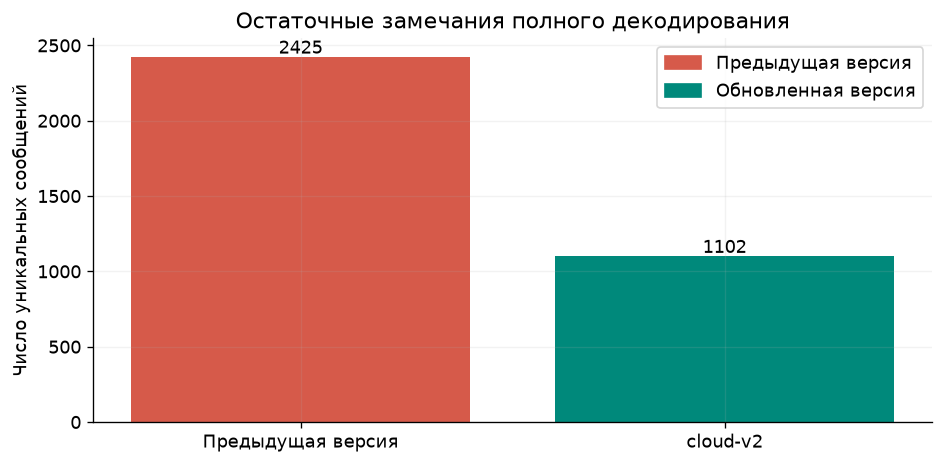

,Строки до 60 минут
old_decoded_rows,6322498
new_decoded_rows,6325385
old_core_rows,6324868
new_core_rows,6327940


station,decode_issues,messages,matched_60min_rows,matched_60min_go_arounds
EDDB,parser_error,9,22,0
EDDF,parser_error,20,215,2
EDDF,unclassified_weather_after_qnh;parser_error,2,14,0
EDDM,parser_error,17,154,1
EDDM,parser_error;visibility_format_outside_pilot_scope,2,0,0
EDDM,parser_value_disagreement_weather,3,0,0
EDDM,unclassified_weather_after_qnh;parser_error,1,0,0
EDDM,visibility_format_outside_pilot_scope,1,4,0
EGCC,parser_error;qnh_group_missing_or_multiple,1,4,0
EGCC,qnh_group_missing_or_multiple,1,6,0


metar_id,station,metar_utc,metar,decode_issues,core_validated,matched_60min_rows,matched_60min_go_arounds
3b144a0cf7a0e0c88ce7a2f034354332a182ca14f8f08b2570dc337c3778e957,EDDB,2021-01-25 03:20:00+00:00,EDDB 250320Z 28007KT 7000 BKN007 00/M01 Q0999 R88/D TEMPO 4500 BR BKN004,parser_error,True,0,0
52a12aa6c9493720f985b1c7c24a2c0f2e3a89ba0c4308cfbb61e59ead60b124,EDDB,2021-01-25 03:50:00+00:00,EDDB 250350Z 27005KT 9000 BKN008 00/M01 Q0999 R88/D TEMPO 4500 BR BKN004,parser_error,True,0,0
3a7fbf1ce8a9099bc5702a52811d37e7b17045533e1d62ef69d4b73fd2542a5e,EDDB,2021-01-25 04:20:00+00:00,COR EDDB 250420Z 26005KT 9999 BKN011 00/M00 Q0999 R88/D BECMG BKN015,parser_error,True,0,0
8df34d2ac5f366a9150bb46747ac2d70ddcfd97175770d2b80f0ddf23bea27ed,EDDB,2021-01-25 04:50:00+00:00,EDDB 250450Z 27003KT 9999 FEW015 BKN028 M00/M01 Q1000 R88/D NOSIG,parser_error,True,0,0
9391554d6a3e70893bcb960a3929cc9625aa930b942f165bb66f78b71c16d2e9,EDDB,2022-07-19 08:20:00+00:00,EDDB 190820Z AUTO 36004KT 280V070 9999 ///////// 29/09 Q1020 RE// BECMG CAVOK,parser_error,True,5,0
a897a1d4b290745eda95976700f49738fca893b7f693d1fe09604981671e9002,EDDB,2022-10-11 08:50:00+00:00,EDDB 110850Z AUTO 26005KT 200V300 9999 FEW011 12/08 Q1025 RE// NOSIG,parser_error,True,6,0
81a87a512b79c6ca25a8455e04001d6a0a972f705308db1f728ebec30e4580ab,EDDB,2022-11-08 08:50:00+00:00,EDDB 080850Z AUTO 19008KT CAVOK 12/09 Q1013 RE// NOSIG,parser_error,True,5,0
2c3dcc034e2d091aa4402eca21fd24c9a37d0839467405b3e3ce0a1088903aed,EDDB,2022-12-06 08:50:00+00:00,EDDB 060850Z AUTO 26006KT 9999 -DZ OVC006 02/01 Q1015 RE// NOSIG,parser_error,True,4,0
b18a8d6d278c1bbabfa3c8f17e5da6fba092a07b22177acfd7631274d2dcef3e,EDDB,2023-01-10 08:50:00+00:00,EDDB 100850Z AUTO 26010KT 9999 BKN016 BKN047 06/04 Q1016 RE//,parser_error,True,2,0
3776dbcecc809b3608963475a56416da786cc0dd14431483ca5aba6933ea99fe,EDDF,2019-11-20 09:20:00+00:00,EDDF 200920Z 08008KT 3500 1500SE BR BKN001 02/01 Q1018 BCMG BKN002,unclassified_weather_after_qnh;parser_error,True,14,0


In [4]:
old_audit=json.loads((R/'19_residual_format_audit.json').read_text(encoding='utf8'))
old_count=old_audit['messages']
new_count=len(remaining)
fig,ax=plt.subplots(figsize=(8,4))
ax.bar(['Предыдущая версия','cloud-v2'],[old_count,new_count],color=[CORAL,GREEN])
for x,value in enumerate([old_count,new_count]):ax.text(x,value+20,str(value),ha='center')
ax.set(ylabel='Число уникальных сообщений',title='Остаточные замечания полного декодирования')
from matplotlib.patches import Patch
ax.legend(handles=[Patch(color=CORAL,label='Предыдущая версия'),Patch(color=GREEN,label='Обновленная версия')])
save('32_cloud_v2_residual_comparison')
display(coverage[['old_decoded_rows','new_decoded_rows','old_core_rows','new_core_rows']].sum().to_frame('Строки до 60 минут'))
readable_table(remaining.groupby(['station','decode_issues']).agg(messages=('metar_id','size'),
    matched_60min_rows=('matched_60min_rows','sum'),matched_60min_go_arounds=('matched_60min_go_arounds','sum')).reset_index())
readable_table(remaining.sort_values(['station','metar_utc']).head(30))


## 4. Проверки совместимости и сохранности

Все 18 439 сообщений первоначальных пилотов проверены по всем ранее
сохраненным полям. Полный архив просмотрен для определения области изменения;
повторно декодированы только сообщения с целевыми группами в наблюдаемой
части до температуры/QNH. Для остальных сообщений модуль v2 вызывает прежний
декодер. При сохранении каждого файла проверены неизменность строк, связей и
полей вне облачной области, а также сохранность всех масок числового качества.

Ниже повторяются 26 семантических тестов и проверяются контрольные суммы
старых и новых файлов. Прогнозные группы и хвост после QNH не используются
для восстановления наблюдаемой облачности.


In [5]:
import unittest,test_decode_metar,test_full_weather_pipeline,test_cloud_v2
outcome=unittest.TextTestRunner(stream=sys.stdout,verbosity=1).run(unittest.TestSuite([
    unittest.defaultTestLoader.loadTestsFromModule(module)
    for module in [test_decode_metar,test_full_weather_pipeline,test_cloud_v2]]))
assert outcome.wasSuccessful() and outcome.testsRun==26
assert application['pilot_rows_unchanged']==18439
assert sha(BASE/'scripts/decode_metar_cloud_v2.py')==application['decoder_sha256']
assert sha(BASE/'scripts/decode_metar.py')==application['original_decoder_sha256']
assert sha(BASE/'scripts/rebuild_cloud_v2.py')==application['implementation_sha256']
for job in application['jobs']:
    for item in job['files']:
        assert sha(DATA/'full_cloud_v2'/item['path'])==item['sha256']
original=json.loads((R/'12_full_integrity.json').read_text(encoding='utf8'))
for item in original['feature_files']:assert sha(DATA/'full/results'/item['name'])==item['sha256']
numeric=json.loads((R/'18_numeric_mask_application.json').read_text(encoding='utf8'))
for item in numeric['files']:assert sha(DATA/'numeric_quality_v1'/item['name'])==item['output_sha256']
display(pd.DataFrame([{'Тестов':outcome.testsRun,'Сообщений пилотов без изменения':18439,
    'Строк базы сохранено':application['rows'],'Удалено строк':0,'Числовые маски сохранены':True}]))


.

.

.

.

.

...

.

.

.

----------------------------------------------------------------------
Ran 26 tests in 0.015s

OK


,Тестов,Сообщений пилотов без изменения,Строк базы сохранено,Удалено строк,Числовые маски сохранены
0,26,18439,6331485,0,True


## 5. Границы результата

Исправлено представление облачных групп, не сами наблюдения. Не выполнены
замена исходных строк, восстановление высоты/количества облаков, импутация,
обучение или оценка влияния на качество модели. Старые версии сохранены для
воспроизводимости аудита. Следующие форматы — погодные сочетания, группы
состояния ВПП, нетипичные хвосты — требуют собственных проверок.

После их разбора необходимо согласовать основной сценарий доступности погоды
на C40. Использовать новые погодные поля вместе с числовыми модельными копиями
из одной версии `full_cloud_v2`, соединяя по `source_row` и SHA-256 входа.
[Отчет версии](../reports/21_cloud_v2_review.md).
